# Figure 4 · Residual reconstruction

Simple vector diagram of the common residual architecture, the two alternative
output paths, and one residual dense block. The output paths belong to two
separately trained networks; they do not share fitted weights.

Source hashes are checked against both recorded full runs before drawing.
No model is imported, constructed or run. Layer details remain in the notes
and export provenance, rather than crowding the schematic.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v02'

In [2]:
FIGSIZE = (7.2, 4.8)
source_paths = [ROOT / 'code' / name for name in
                ['residual_baseline.py', 'train_paired.py', 'paired_sample.py']]
provenances = [ROOT / 'runs' / name / 'provenance.json' for name in
              ['residual-full50-s20261016', 'direct5-full50-s20261016']]
for provenance in provenances:
    verified_sources(provenance, ['residual_baseline.py', 'train_paired.py', 'paired_sample.py'])
print('Verified model, training and normalization sources against both full runs.')


Verified model, training and normalization sources against both full runs.


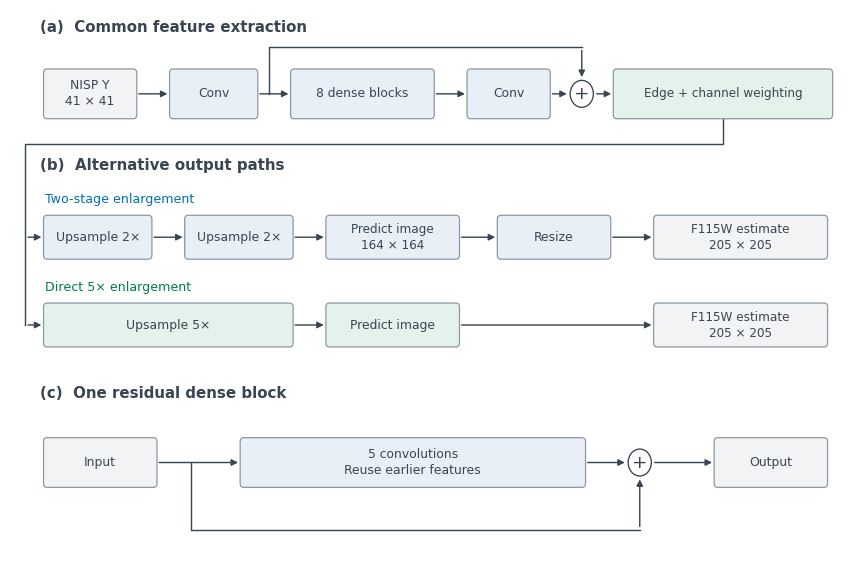

In [3]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Ellipse
INK='#394553'; BLUE='#E8EFF7'; TEAL='#E4F2EC'; GRAY='#F1F3F5'

def node(x,y,w,h,text,fill=BLUE,size=7.4):
    ax.add_patch(FancyBboxPatch((x,y),w,h,
        boxstyle='round,pad=0.025,rounding_size=0.07',
        facecolor=fill,edgecolor='#8B98A5',linewidth=.75,zorder=3))
    ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=size,
            linespacing=1.3,color=INK,zorder=4)

def link(start,end):
    ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',mutation_scale=8,
        color=INK,linewidth=.85,shrinkA=2,shrinkB=2,zorder=2))

def addition(x,y):
    ax.add_patch(Ellipse((x,y),.46,.46,facecolor='white',edgecolor=INK,lw=.8,zorder=3))
    ax.text(x,y,'+',ha='center',va='center',fontsize=11,color=INK,zorder=4)

fig,ax=plt.subplots(figsize=FIGSIZE)
fig.subplots_adjust(left=.025,right=.985,top=.98,bottom=.025)
ax.set(xlim=(-.45,16),ylim=(0,9.4));ax.axis('off')

# Common architecture; the two variants are trained independently.
ax.text(.1,9.05,'(a)  Common feature extraction',fontsize=9,fontweight='semibold',color=INK)
node(.2,7.6,1.8,.8,'NISP Y\n41 × 41',GRAY)
node(2.7,7.6,1.7,.8,'Conv')
node(5.1,7.6,2.8,.8,'8 dense blocks')
node(8.6,7.6,1.6,.8,'Conv')
addition(10.85,8.0)
node(11.5,7.6,4.3,.8,'Edge + channel weighting',TEAL,size=7.2)
for start,end in [((2,8),(2.7,8)),((4.4,8),(5.1,8)),((7.9,8),(8.6,8)),
                  ((10.2,8),(10.62,8)),((11.08,8),(11.5,8))]:link(start,end)
ax.plot([4.65,4.65,10.85],[8,8.8,8.8],color=INK,lw=.85,zorder=1)
link((10.85,8.8),(10.85,8.23))

# The final resize acts on a reconstructed image in the two-stage variant.
ax.plot([13.65,13.65,-.2,-.2],[7.6,7.15,7.15,4.05],color=INK,lw=.85,zorder=1)
ax.text(.1,6.7,'(b)  Alternative output paths',fontsize=9,fontweight='semibold',color=INK)
for y in [5.55,4.05]:link((-.2,y),(.2,y))
ax.text(.2,6.14,'Two-stage enlargement',fontsize=7.6,color='#0072B2')
node(.2,5.2,2.1,.7,'Upsample 2×')
node(3.0,5.2,2.1,.7,'Upsample 2×')
node(5.8,5.2,2.6,.7,'Predict image\n164 × 164',size=7.2)
node(9.2,5.2,2.2,.7,'Resize')
node(12.3,5.2,3.4,.7,'F115W estimate\n205 × 205',GRAY,size=7.2)
for start,end in [(2.3,3.0),(5.1,5.8),(8.4,9.2),(11.4,12.3)]:link((start,5.55),(end,5.55))
ax.text(.2,4.64,'Direct 5× enlargement',fontsize=7.6,color='#007C59')
node(.2,3.7,4.9,.7,'Upsample 5×',TEAL)
node(5.8,3.7,2.6,.7,'Predict image',TEAL)
node(12.3,3.7,3.4,.7,'F115W estimate\n205 × 205',GRAY,size=7.2)
link((5.1,4.05),(5.8,4.05));link((8.4,4.05),(12.3,4.05))

# Inset: dense feature reuse and the residual addition, without per-layer widths.
ax.text(.1,2.8,'(c)  One residual dense block',fontsize=9,fontweight='semibold',color=INK)
node(.2,1.3,2.2,.8,'Input',GRAY)
node(4.1,1.3,6.8,.8,'5 convolutions\nReuse earlier features')
addition(12,1.7)
node(13.5,1.3,2.2,.8,'Output',GRAY)
link((2.4,1.7),(4.1,1.7));link((10.9,1.7),(11.77,1.7));link((12.23,1.7),(13.5,1.7))
ax.plot([3.1,3.1,12],[1.7,.55,.55],color=INK,lw=.85,zorder=1)
link((12,.55),(12,1.47))
plt.show()


In [4]:
paths = export(fig, f'fig04_residual_architecture_{VERSION}', '04_residual_architecture.ipynb',
    [*source_paths, *provenances],
    dict(figsize=FIGSIZE, blocks=8, features=64, growth=32,
         parameters={'two_stage':2332177, 'direct5':2959953},
         two_stage='PixelShuffle 2x, PixelShuffle 2x, reconstruction at 164x164, bilinear resize to 205x205',
         direct5='PixelShuffle 5x, reconstruction at 205x205',
         representation='signed linear normalization with training-only scales',
         loss='mean absolute error over valid target pixels, averaged per object',
         display='simplified common architecture and alternative output paths; no overall title'),
    status='Figure 4: simplified schematic verified against both residual full runs')


Exported: fig04_residual_architecture_v02.pdf, fig04_residual_architecture_v02.svg, fig04_residual_architecture_v02.png


## Working caption

Residual network for reconstructing F115W images from NISP observations.
(a) Both variants extract features using eight residual dense blocks, followed
by edge filtering and learned weighting of the feature maps. (b) Two separately
trained variants use different enlargement paths. The first enlarges twice by
2×, predicts an image on a 164 × 164 grid, then resizes it to 205 × 205; the
second enlarges directly by 5× and predicts on the target grid. (c) Within each
dense block, convolutions reuse earlier features and add a learned correction
to the input. Plus symbols denote this addition.

## Implementation details

- Both variants have the same feature-extraction architecture, with 64 channels
  on the native 41 × 41 grid. They are fitted separately.
- There are eight single residual dense blocks (not nested RRDBs). Each has
  five 3 × 3 convolutions: the first four add 32 feature maps each; the fifth
  combines the block input and previous features back into 64 channels.
  LeakyReLU with slope 0.2 follows the first four convolutions.
- A trunk convolution combines the block outputs, then adds the initial feature
  maps before edge filtering. This is the long residual connection in panel (a).
- The edge module applies the fixed 3 × 3 kernel with center 8 and all neighbors
  −1 to each feature map, adds the response to that map, and applies learned
  3 × 3 and 1 × 1 convolutions. Global average pooling and two 1 × 1 convolutions
  produce sigmoid channel weights multiplying the enhanced features.
- Each enlargement stage learns additional channels with a 3 × 3 convolution,
  then uses PixelShuffle to rearrange them into a finer spatial grid. LeakyReLU
  follows the shuffle. The original head has two 2× stages, then reconstructs
  the image before its final bilinear resize. The direct head has one 5× stage.
- Reconstruction uses two 3 × 3 convolutions, 64 → 64 → 1, with LeakyReLU
  between them. Both models preserve signed output intensities without clipping.
- The NISP image is the only network input; invalid input values are zero-filled.
  Target validity masks define the loss. Normalization is linear, with constants
  fitted only on the training sample.
- Both full runs use 50 epochs, batch size 8, Adam with a OneCycle maximum learning
  rate of 1e-4, and masked L1 loss. The gradient norm is logged, but not clipped
  to a finite threshold. All 2,118 validation objects select the checkpoint.
- Parameter counts are 2,332,177 and 2,959,953. The comparison changes capacity
  and computation as well as enlargement path. Same-seed initialization matches
  the trunk but not the final reconstruction-layer weights (different RNG position).
